# Triage hand-off — routing to language specialists

[Open Colab](https://colab.research.google.com/) and choose **File → Upload notebook** to open this English copy.

**Audience** — Developers new to agents who are familiar with Python functions and async/await.

**Learning objective** — Build a triage agent that identifies the requested language, delegates to a specialist, and returns the specialist's answer.

**Sequence** — Set up the environment, define inputs and agents, run the workflow, check the results, then try an exercise.

[Source code](../src/main.py) · [Example guide](../README.md) · [Environment setup](../../../../../docs/setup.md)

### Pattern architecture

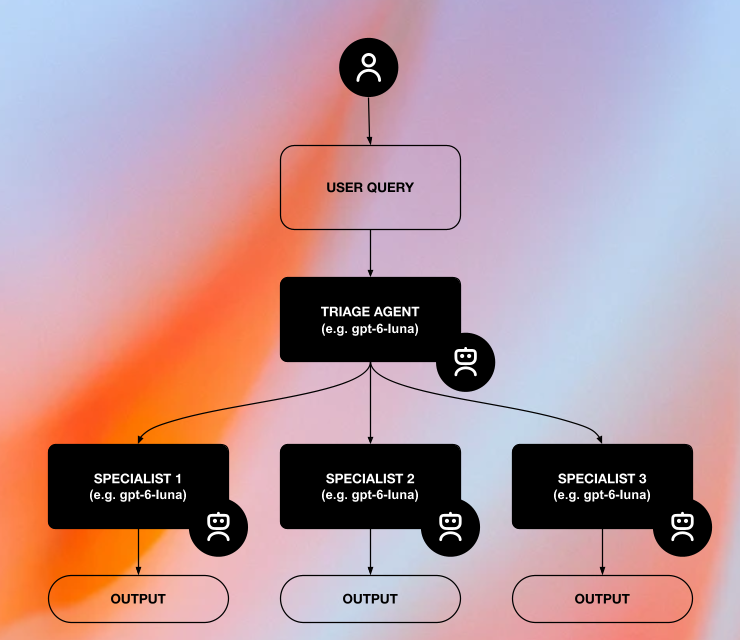

### From diagram to code

| Diagram element | Implementation | Role |
| --- | --- | --- |
| User Query | `question` | User request specifying a response language |
| Triage Agent | `triage_agent` | Selects the appropriate specialist |
| Specialists | `french_agent`, `spanish_agent`, `english_agent` | Respond in the selected language |
| Hand-off routes | `triage_agent.handoffs` | Lists agents eligible to receive control |
| Output | `result.final_output` | Final answer from the selected specialist |

#### Execution flow

1. `Runner.run()` passes the request to `triage_agent`.
2. The triage agent chooses the handoff tool for the requested language.
3. The SDK transfers control to the selected specialist.
4. Inspect `result.last_agent` and the run items to confirm the handoff.

#### How the example implements the diagram

The triage agent invokes the SDK handoff directly, without first producing a separate classification. After the transfer, the specialist owns the rest of the run and writes the final answer.

## 1. Set up the environment

### Colab

1. In Colab, choose **File → Upload notebook** and select this `.ipynb` file. A CPU runtime is sufficient. You can run it without cloning the repository or mounting Google Drive.
2. The setup cell installs `openai-agents==0.22.1` and `python-dotenv` if needed. If you already imported a different SDK version, restart the runtime and run from the top.
3. For live calls, open **Secrets** (the key icon in the left sidebar), add your existing key as `OPENAI_API_KEY`, and enable access for this notebook. Keep keys out of code cells. Your local `.env.local` file is not copied into Colab.

### Local Jupyter

Install the shared notebook environment with `uv` and select its kernel. Existing environment variables take precedence. If a `.env.local` file exists in the current directory or a parent, the notebook reads additional settings from it. Offline exercises require neither the file nor a key.

### Run settings

The default `RUN_API=False` builds the agents and runs offline exercises without reading Secrets or calling the API. To see live results, set `RUN_API=True` in the next cell and run the following cells in order. Key lookup order is **environment → optional `.env.local` → Colab Secrets**. The notebook never prints or saves key values. Model calls and web searches may incur charges. Jupyter supports top-level `await` in its existing event loop.

The standalone example later in the notebook has its own `run_api=True` argument, independent of `RUN_API`.


In [ ]:
import os
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

# Install only in Colab. Local environments use requirements-notebooks.txt.
try:
    import google.colab
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    try:
        dependencies_ready = (
            version("openai-agents") == "0.22.1"
            and version("python-dotenv").split(".")[0] == "1"
        )
    except PackageNotFoundError:
        dependencies_ready = False
    if not dependencies_ready:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "--quiet",
            "openai-agents==0.22.1", "python-dotenv>=1,<2",
        ])

from agents import Agent, Runner, set_tracing_disabled
from dotenv import find_dotenv, load_dotenv


def load_environment(*, run_api: bool) -> str:
    """Load optional local settings; request Colab Secrets only for live runs."""
    env_path = find_dotenv(filename=".env.local", usecwd=True)
    if env_path:
        load_dotenv(env_path, override=False)

    if run_api and not os.getenv("OPENAI_API_KEY", "").strip():
        try:
            from google.colab import userdata
        except ImportError:
            raise RuntimeError(
                "Set OPENAI_API_KEY in your environment or .env.local before enabling API calls."
            ) from None

        try:
            key = userdata.get("OPENAI_API_KEY")
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            raise RuntimeError(
                "In Colab Secrets, add OPENAI_API_KEY and enable Notebook access, "
                "then rerun this cell."
            ) from None
        if not isinstance(key, str) or not key.strip():
            raise RuntimeError("The OPENAI_API_KEY secret is empty.")
        os.environ["OPENAI_API_KEY"] = key.strip()

    return os.getenv("AGENT_MODEL", "gpt-6-luna")


RUN_API = False  # Set True for the walkthrough's API and web search calls.
MODEL = load_environment(run_api=RUN_API)
set_tracing_disabled(True)
print({"environment": "Colab" if IN_COLAB else "local", "model": MODEL, "api_enabled": RUN_API})


## 2. Define the specialists and triage agent

The triage agent can transfer control to agents registered in `handoffs`. Distinct instructions give the specialists different roles even when they use the same model.

In [ ]:
french_agent = Agent(
    name="French specialist",
    model=MODEL,
    instructions="Reply only in French, in one sentence.",
)

spanish_agent = Agent(
    name="Spanish specialist",
    model=MODEL,
    instructions="Reply only in Spanish, in one sentence.",
)

english_agent = Agent(
    name="English specialist",
    model=MODEL,
    instructions="Reply only in English, in one sentence.",
)

triage_agent = Agent(
    name="Language triage",
    model=MODEL,
    instructions=(
        "Always hand off to the specialist matching the requested response "
        "language. Do not answer yourself."
    ),
    handoffs=[french_agent, spanish_agent, english_agent],
)

question = "Please greet a new student in French."

assert len(triage_agent.handoffs) == 3

## 3. Run the handoff (API call)

This exercise reduces the upstream interactive conversation to one request.

In [ ]:
result = None

if RUN_API:
    result = await Runner.run(triage_agent, question, max_turns=4)

    print(result.final_output)
else:
    print("API call skipped. Set RUN_API=True to enable it.")

## 4. Verify the handoff

Check the handoff event and final agent identity to establish which agent answered.

In [ ]:
if result is not None:
    handoffs = [
        item for item in result.new_items if item.type == "handoff_output_item"
    ]

    assert handoffs, "No handoff to a specialist agent occurred."
    assert result.last_agent.name == "French specialist"

    print({"handoffs": len(handoffs), "final_agent": result.last_agent.name})

## 5. Run the workflow as a Python module with `main()`

The preceding cells walk through the workflow step by step. The next cell packages the same workflow as an independent Python module. Once the dependencies are installed, you can start with this cell because it defines its own agents and variables.

Keep `main()` as the entry point and handle a single request. The reusable `route_question()` function lets the triage agent hand control to a specialist that writes the final response. Language routing happens through the SDK handoff, without Python branching on language or manually calling a specialist.

| Component | Responsibility |
| --- | --- |
| `build_triage_agent()` | Builds three language specialists and a triage agent with handoffs |
| `route_question()` | Runs the request, verifies the handoff and final agent, and returns the result |
| `main()` | Loads settings, determines whether to run, passes the input, and prints the result |

The reusable function accepts any registered specialist and returns its name, so you can ask for Spanish or English as well as French. It verifies which specialist answered. Evaluating whether the answer uses the requested language would require a separate check.

The default is `run_api=False`. Defining the functions makes no API calls. Use `main(run_api=...)` to choose live execution.


In [ ]:
import asyncio
import os

from agents import Agent, Runner, set_tracing_disabled
from dotenv import find_dotenv, load_dotenv


def build_triage_agent(model: str) -> Agent:
    """Create a triage agent and its three language specialists."""
    french_agent = Agent(
        name="French specialist",
        model=model,
        instructions="Reply only in French, in one sentence.",
    )

    spanish_agent = Agent(
        name="Spanish specialist",
        model=model,
        instructions="Reply only in Spanish, in one sentence.",
    )

    english_agent = Agent(
        name="English specialist",
        model=model,
        instructions="Reply only in English, in one sentence.",
    )

    return Agent(
        name="Language triage",
        model=model,
        instructions=(
            "Always hand off to the specialist matching the requested response "
            "language. Do not answer yourself."
        ),
        handoffs=[french_agent, spanish_agent, english_agent],
    )


async def route_question(
    question: str,
    *,
    model: str,
    max_turns: int = 4,
) -> dict:
    """Route one request and return its answer and handoff metadata."""
    triage_agent = build_triage_agent(model)
    result = await Runner.run(
        triage_agent,
        question,
        max_turns=max_turns,
    )

    handoffs = [
        item
        for item in result.new_items
        if item.type == "handoff_output_item"
    ]

    if not handoffs:
        raise RuntimeError("No handoff to a specialist agent occurred.")

    specialist_names = {agent.name for agent in triage_agent.handoffs}

    if result.last_agent.name not in specialist_names:
        raise RuntimeError("The final agent is not a language specialist.")

    answer = str(result.final_output)

    if not answer.strip():
        raise RuntimeError("The specialist returned an empty answer.")

    return {
        "answer": answer,
        "handoffs": len(handoffs),
        "final_agent": result.last_agent.name,
    }


def load_environment(*, run_api: bool) -> str:
    """Load optional local settings; request Colab Secrets only for live runs."""
    env_path = find_dotenv(filename=".env.local", usecwd=True)
    if env_path:
        load_dotenv(env_path, override=False)

    if run_api and not os.getenv("OPENAI_API_KEY", "").strip():
        try:
            from google.colab import userdata
        except ImportError:
            raise RuntimeError(
                "Set OPENAI_API_KEY in your environment or .env.local before enabling API calls."
            ) from None

        try:
            key = userdata.get("OPENAI_API_KEY")
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            raise RuntimeError(
                "In Colab Secrets, add OPENAI_API_KEY and enable Notebook access, "
                "then rerun this cell."
            ) from None
        if not isinstance(key, str) or not key.strip():
            raise RuntimeError("The OPENAI_API_KEY secret is empty.")
        os.environ["OPENAI_API_KEY"] = key.strip()

    return os.getenv("AGENT_MODEL", "gpt-6-luna")


async def main(
    question: str = "Please greet a new student in French.",
    *,
    run_api: bool = False,
    max_turns: int = 4,
) -> dict | None:
    """Load configuration, run language routing, and print its result."""
    model = load_environment(run_api=run_api)
    set_tracing_disabled(True)

    if not run_api:
        print("API call skipped. Pass run_api=True to enable it.")
        return None

    result = await route_question(
        question,
        model=model,
        max_turns=max_turns,
    )

    print(result["answer"])
    print({
        "handoffs": result["handoffs"],
        "final_agent": result["final_agent"],
    })

    return result


### Calling the workflow in a notebook

Use `await main(...)` in Jupyter's existing event loop. The next cell loads settings and skips API calls by default. Set `run_api=True` to start a fresh, billable run with new conversation history.


In [ ]:
standalone_result = await main(
    question="Please greet a new student in French.",
    run_api=False,  # Set to True to run this standalone workflow.
    max_turns=4,
)


### Running `triage_agent.py`

1. Copy the **entire function definition cell** into `triage_agent.py`. Leave the notebook-only `await main(...)` invocation in the notebook.

2. Add the following entry point at the bottom of the file. API calls run only when you pass `--run-api`.

   ```python
   if __name__ == "__main__":
       import argparse

       parser = argparse.ArgumentParser(description="Route a language request.")
       parser.add_argument("--run-api", action="store_true")
       args = parser.parse_args()

       asyncio.run(main(run_api=args.run_api))
   ```

3. Activate the virtual environment containing the exercise dependencies and run the commands below. For live calls, set `OPENAI_API_KEY` in the environment or the optional `.env.local` file.

   ```bash
   python triage_agent.py            # Check configuration; skip API calls
   python triage_agent.py --run-api  # Run the workflow; API costs apply
   ```

In another module, use `from triage_agent import route_question` and call `await route_question(question, model=...)`. The caller supplies environment variables and tracing settings. The `if __name__ == "__main__":` guard prevents execution on import.

This standalone example is separate from `src/main.py`. When distributing it, retain the notebook attribution and the repository's `THIRD_PARTY_NOTICES.md`.


## Try it yourself

Change the question to ask for an answer in Spanish. Update the expected agent name in the final check and verify which specialist actually received the handoff.

## Changes from upstream and limitations

This version uses one `Runner.run()` call in place of the upstream streaming, multi-turn loop. A handoff transfers ownership of the response to the receiving agent.

## Sources

- [Local source](../src/main.py)
- [Official OpenAI example](https://github.com/openai/openai-agents-python/blob/25af629b3c877ba3d0e95189141bb636b21167a5/examples/agent_patterns/routing.py)
- [Agents SDK guide](https://developers.openai.com/api/docs/guides/agents/sdk)
- [Agents guide](https://developers.openai.com/api/docs/guides/agents)

This notebook adapts the official example for hands-on learning. Model outputs vary between runs.